# 07 — Portfolio site figure: declared winners vs. the pooled model

One figure for the portfolio site, showing the project's core point with the Stage 2 hierarchical model: A/B "winners" declared from raw CTR win by less than the raw numbers suggest, once each test's noise is put in the context of all the others.

- **Data view:** `v_exploratory_clean` (standard filters), exploratory sample only. Row order `ORDER BY clickability_test_id, created_at`, identical to notebook 03 Task 4, so arm *i* here is `p_arm[i]` in the fit.
- **Fit:** `idata/full_sample_nuts_tune4000_ta095_draws4000.nc`, the settled Stage 2 Task 4 configuration (tune=4000, target_accept=0.95, draws=4000, 4 chains). Loaded from disk, never refit here; `p_arm` is read in chunks (`site_figures.pooled_top_two`) per the 16GB-machine convention.
- Helpers: `src/clickworthy/site_figures.py`.

## Definitions (fixed before looking at results)

- Per test, the **naive winner** and **runner-up** are its top two arms by raw CTR.
- **Naive verdict:** `classical.two_proportion_test` (score z-test), unadjusted p < 0.05 → "declared winner". Benjamini–Hochberg across all 3,823 top-two comparisons is reported alongside for context.
- **Pooled verdict:** from the posterior `p_arm` draws, P(p_winner > p_runner-up) and the relative lift p_winner / p_runner-up − 1 (posterior median, equal-tailed 95% credible interval). **"Still clear" = P ≥ 0.95.**

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

from clickworthy import data_access as da
from clickworthy import site_figures as sf

FIT_PATH = Path("../idata/full_sample_nuts_tune4000_ta095_draws4000.nc")
OUT_DIR = Path("../figures/site")

con = da.connect()
full_df = con.execute(
    f"SELECT * FROM {da.CLEAN_VIEW} ORDER BY clickability_test_id, created_at"
).df()

# Arm order must match the fit exactly: no created_at ties within a test (so the
# ORDER BY is deterministic), and the fit's observed clicks equal ours row for row.
assert not full_df.duplicated(["clickability_test_id", "created_at"]).any()
with xr.open_dataset(FIT_PATH, group="observed_data", engine="h5netcdf") as od:
    assert np.array_equal(od["clicks_obs"].values, full_df["clicks"].to_numpy())
with xr.open_dataset(FIT_PATH, group="posterior", engine="h5netcdf") as ds:
    N_DRAWS = ds.sizes["chain"] * ds.sizes["draw"]
print(f"{full_df['clickability_test_id'].nunique()} tests, {len(full_df)} arms, "
      f"{N_DRAWS} posterior draws; arm order matches the fit")

3823 tests, 18388 arms, 16000 posterior draws; arm order matches the fit


In [2]:
naive = sf.top_two_by_ctr(full_df)
pooled = sf.pooled_top_two(str(FIT_PATH), naive["w_arm_idx"], naive["r_arm_idx"])
comparison = pd.concat([naive, pooled], axis=1)
declared = comparison[comparison["declared"]].copy()
declared["lift_ratio"] = declared["pooled_lift_median"] / declared["naive_lift"]

n_tests, n_declared = len(comparison), len(declared)
n_clear = (declared["p_better"] >= sf.CLEAR_THRESHOLD).sum()
print(f"tests: {n_tests}")
print(f"declared winners (p < 0.05): {n_declared} ({n_declared / n_tests:.1%}); "
      f"survive BH: {comparison['declared_bh'].sum()}")
print(f"declared and still clear (P >= 0.95): {n_clear}/{n_declared} = {n_clear / n_declared:.1%}; "
      f"not clear: {n_declared - n_clear} ({1 - n_clear / n_declared:.1%})")
print(f"median naive lift {declared['naive_lift'].median():+.1%}, "
      f"median pooled lift {declared['pooled_lift_median'].median():+.1%}, "
      f"median pooled/naive ratio {declared['lift_ratio'].median():.2f} "
      f"(IQR {declared['lift_ratio'].quantile(.25):.2f}-{declared['lift_ratio'].quantile(.75):.2f})")
print(f"declared winners whose pooled lift < naive lift: {(declared['lift_ratio'] < 1).mean():.0%}")

/opt/homebrew/Caskroom/miniforge/base/envs/clickworthy/lib/python3.11/site-packages/statsmodels/stats/proportion.py:2112: RuntimeWarning: invalid value encountered in scalar divide
  ratio = p1 / p2
/opt/homebrew/Caskroom/miniforge/base/envs/clickworthy/lib/python3.11/site-packages/statsmodels/stats/proportion.py:2113: RuntimeWarning: invalid value encountered in scalar divide
  odds_ratio = p1 / (1 - p1) / p2 * (1 - p2)
/opt/homebrew/Caskroom/miniforge/base/envs/clickworthy/lib/python3.11/site-packages/statsmodels/stats/weightstats.py:838: RuntimeWarning: invalid value encountered in scalar divide
  zstat = value / std


tests: 3823
declared winners (p < 0.05): 382 (10.0%); survive BH: 67
declared and still clear (P >= 0.95): 365/382 = 95.5%; not clear: 17 (4.5%)
median naive lift +64.2%, median pooled lift +45.3%, median pooled/naive ratio 0.76 (IQR 0.66-0.82)
declared winners whose pooled lift < naive lift: 100%


## Stage-1 results and the choice of framing

**Counts** (output above): 3,823 tests; 382 (10.0%) have a declared winner at p < 0.05, 67 of which survive BH. Of the 382, **365 (95.5%) are still clear** after pooling at P ≥ 0.95; 17 (4.5%) are not. All 67 BH survivors stay clear. Median naive lift among declared winners is **+64%**, median pooled lift **+45%** (median pooled/naive ratio 0.76, IQR 0.66–0.82), and the pooled lift is smaller than the naive lift for **every one** of the 382.

**Two framings were considered:**

1. *"Winners often aren't real"*: declared winners frequently stop being clear after pooling. **Dropped.** At the pre-set bar (P ≥ 0.95), only 4.5% of declared winners lose clarity, well below the ~20% that was set in advance as the point where this story would need to change. The bar was not moved after seeing the results to rescue this framing.
2. *"Winners win by less than they seem"*: every declared winner's lift shrinks, by about a quarter at the median. **Kept.** It is true for all 382 and is the direct, archive-wide signature of the winner's curse that partial pooling corrects.

**Robustness note (not the headline).** P ≥ 0.95 is roughly a one-sided 5% bar, while the naive test is two-sided at 5%, so the pooled bar is the more lenient of the two. At the matched bar P ≥ 0.975 (computed below), 271/382 stay clear and about 29% do not. That count depends on the bar; the shrinkage of every lift does not.

**What is empirical here.** That *every* declared winner's lift shrinks is expected by construction: the `delta_arm` prior is symmetric and centered at zero, so partial pooling pulls each arm's effect toward its test baseline, and an extreme winner/runner-up gap can only narrow. The empirical finding is the *size* of the shrinkage, about a quarter at the median (ratio 0.76, +64% → +45%), which depends on the fitted global `sigma` relative to each test's noise.

In [3]:
n_clear_975 = (declared["p_better"] >= 0.975).sum()
print(f"P >= 0.975: {n_clear_975}/{n_declared} still clear; "
      f"{1 - n_clear_975 / n_declared:.1%} not clear")

P >= 0.975: 271/382 still clear; 29.1% not clear


### A curiosity: identical-headline "winners"

Under the first (dropped) framing's exemplar rule (declared, not clear after pooling, lift ratio nearest that group's median), three of the top five candidates had **identical headline text** in the winner and runner-up arms. In two of them the arms differ only in image (`eyecatcher_id`). In one (`5538ee65…`, *"14 years ago, she quit her job and started farming…"*) headline text **and** `eyecatcher_id` are identical: a true duplicate arm that produced a naive "+93% lift, p = 0.042". This is a useful reminder of what pure noise can look like at p < 0.05. It is also why the exemplar rule below excludes identical-text pairs. Across all 382 declared winners, the share with identical winner/runner-up text is shown below.

In [4]:
same_text = declared["w_headline"] == declared["r_headline"]
print(f"declared winners with identical winner/runner-up headline text: "
      f"{same_text.sum()}/{n_declared} ({same_text.mean():.1%})")
(declared[same_text & (declared["p_better"] < sf.CLEAR_THRESHOLD)]
 [["clickability_test_id", "w_headline", "w_clicks", "w_impressions", "r_clicks",
   "r_impressions", "naive_lift", "p_raw", "pooled_lift_median", "p_better"]])

declared winners with identical winner/runner-up headline text: 134/382 (35.1%)


,clickability_test_id,w_headline,w_clicks,w_impressions,r_clicks,r_impressions,naive_lift,p_raw,pooled_lift_median,p_better
657,5319e3ac234dde8190000026,Recognize: 58% Of Women Use Birth Control For ...,23,2485,11,2555,1.149808,0.031856,0.468184,0.941688
2591,5450524a7ccd9dbdd3000047,People Are Finally Starting To See Men As More...,33,5631,18,5612,0.827147,0.036348,0.426802,0.946625
2855,54720673aecbbe2805000023,You See This Store Everywhere. Did You Notice ...,24,2993,12,3106,1.075510,0.034208,0.451160,0.937125
3065,5491c99030613400219a0000,It's Not Just Hunger Anymore. There's A Bigger...,16,2847,6,2888,1.705070,0.030039,0.448668,0.913875
3363,54d155da3536350019020000,Brilliant Harvard Psychologist Explains How To...,24,1582,10,1498,1.272566,0.024139,0.452585,0.937375
3789,5538ee65636230001c940000,"14 years ago, she quit her job and started far...",27,2499,14,2494,0.924713,0.042153,0.436438,0.937500


## Exemplar selection (rules fixed before ranking)

- Declared winner (naive p < 0.05), any pooled verdict.
- Winner and runner-up have **different** headline text, both under 90 characters.
- Ranked by closeness of the pooled/naive lift ratio to the median ratio over **all** 382 declared winners (0.76), so the exemplar is typical, not the most dramatic.
- Take #1 unless a headline is unreadable or confusing out of context.

In [5]:
candidates, median_ratio = sf.exemplar_candidates(comparison)
print(f"median pooled/naive ratio, all declared winners: {median_ratio:.3f}\n")
for rank, (_, r) in enumerate(candidates.iterrows(), start=1):
    print(f"#{rank} [{r.clickability_test_id}] {r.n_arms} arms, ratio {r.lift_ratio:.3f}")
    print(f"   W: {r.w_headline!r}  {r.w_clicks}/{r.w_impressions} = {r.w_ctr:.2%}")
    print(f"   R: {r.r_headline!r}  {r.r_clicks}/{r.r_impressions} = {r.r_ctr:.2%}")
    # Whole-percent lifts, same rounding as the figure's annotations.
    print(f"   naive {r.naive_lift:+.0%}, p = {r.p_raw:.2g} | pooled {r.pooled_lift_median:+.0%} "
          f"[{r.pooled_lift_low:+.0%}, {r.pooled_lift_high:+.0%}], P(better) = {r.p_better:.4f}\n")

exemplar = candidates.iloc[0]

median pooled/naive ratio, all declared winners: 0.759

#1 [5149eb48b245f00002007fdd] 4 arms, ratio 0.759
   W: '10 Amazing International Photos That Will Give You Some Perspective'  103/5360 = 1.92%
   R: 'I Never Thought Toys Could Tell You So Much About How The World Works'  47/5522 = 0.85%
   naive +126%, p = 1.7e-06 | pooled +95% [+45%, +166%], P(better) = 1.0000

#2 [54b69eea39316500244a0000] 6 arms, ratio 0.757
   W: 'A Question All Couples Should Talk About Before They Get In Too Deep'  72/4766 = 1.51%
   R: "Out Of 9500 Women, Almost All Of Them Got A Man's Opinion About This Decision"  44/4825 = 0.91%
   naive +66%, p = 0.0073 | pooled +50% [+8%, +109%], P(better) = 0.9924

#3 [543c53111ca6b8590800000d] 4 arms, ratio 0.762
   W: '8 Ugly Facts About How The Fashion Industry Creates Beauty'  79/3005 = 2.63%
   R: '8 Reasons Why Behind That Beautiful Face Could Be A Really Sad Story'  46/3062 = 1.50%
   naive +75%, p = 0.002 | pooled +57% [+14%, +117%], P(better) = 0.9978

#4 [5

**Pick: #1** (`5149eb48…`, *"10 Amazing International Photos That Will Give You Some Perspective"* vs. *"I Never Thought Toys Could Tell You So Much About How The World Works"*). Both headlines read clearly out of context, so there was no reason to skip it. Its ratio (0.759) is essentially the archive median. Note that it is a clear winner under both views. The point it illustrates is that a typical winner is still overstated, not that it is fake.

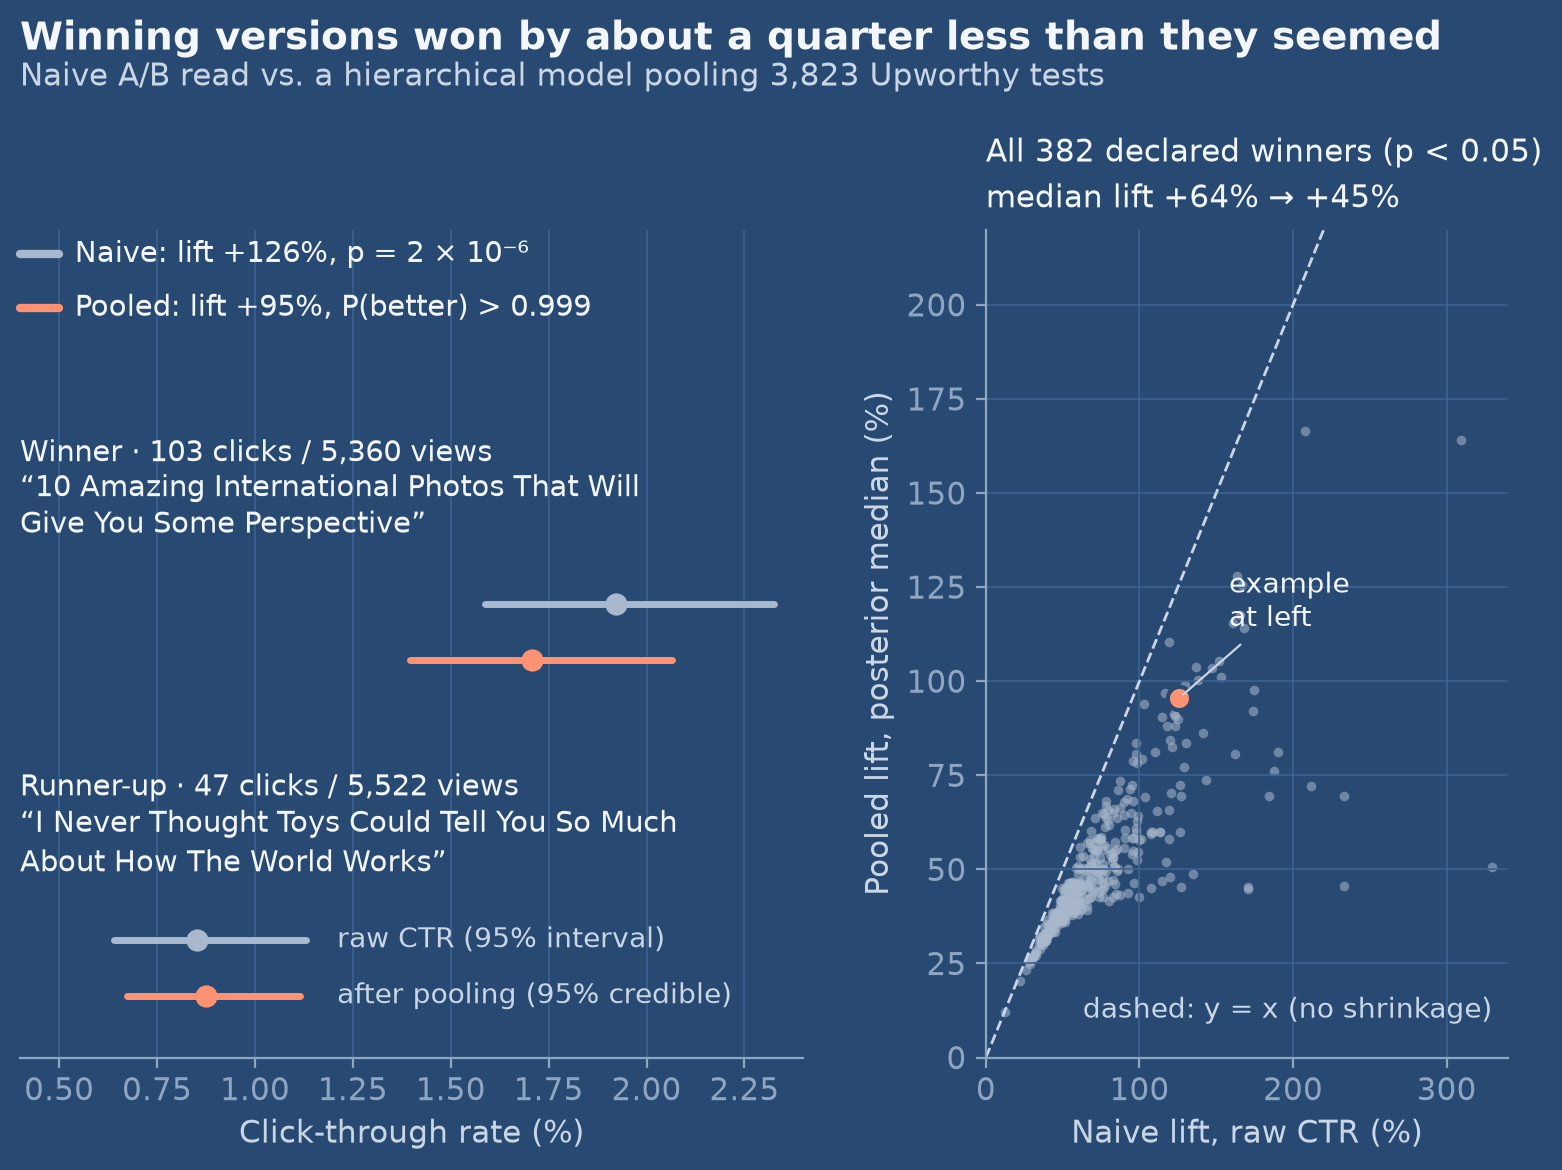

In [6]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
fig = sf.plot_site_figure(exemplar, declared, N_DRAWS)
fig.savefig(OUT_DIR / "clickworthy_winners.png", dpi=200)
fig.savefig(OUT_DIR / "clickworthy_winners.pdf")
plt.show()

Saved to `figures/site/clickworthy_winners.png` (1600×1200 px, 4:3) and `.pdf`. Minimum text size is 10 pt; legibility was checked on a 600 px-wide downscale.

**Wording:** 134 of the 382 declared winners share headline text with their runner-up and differ only by image, so the title and caption say "version", not "headline". The left panel keeps headline text because the exemplar's two arms do have different headlines.

**Site caption:** *Across 382 Upworthy A/B tests with a 'winner' at p < 0.05, a hierarchical model that pools evidence across all 3,823 tests shrinks the winning lift by about a quarter at the median (+64% → +45%).*